# Klasifikasi Citra Serangga Menggunakan CNN dengan Transfer Learning EfficientNetB0

**Laporan Akhir Semester**
**Mata Kuliah:** Kecerdasan Buatan

**Anggota Kelompok**

| No | Nama | NIM |
|----|------|-----|
| 1 | Aulia Arief | 2407112796 |
| 2 | Naufal Huseini | 2407114249 |
| 3 | Herva Sulistia | 2407110856 |
| 4 | Habil Rahman Soleh | 2407110968 |
| 5 | Jefri Mulia Rezki | 2407111762 |

---

**Ringkasan.** Laporan ini memuat proses pembuatan model *Convolutional Neural Network* (CNN) untuk mengklasifikasikan citra serangga. Data yang digunakan adalah dataset *Insect Identification from Habitus Images* dari Kaggle, yang labelnya berupa kode taksonomi GBIF. Model dibangun dengan *transfer learning* menggunakan EfficientNetB0 dan dilatih dalam dua fase, yaitu *feature extraction* dan *fine-tuning*. Setiap tahap pada notebook ini dilengkapi penjelasan tujuan, alasan pemilihan metode, dan hasil yang diperoleh.

## 1. Setup Environment & GPU
Tahap ini bertujuan menyiapkan lingkungan kerja. Pustaka yang digunakan adalah TensorFlow/Keras untuk membangun dan melatih model, NumPy untuk operasi numerik, serta Matplotlib untuk visualisasi. TensorFlow/Keras dipilih karena menyediakan model pretrained EfficientNetB0 yang digunakan pada tahap 11.

Notebook dijalankan di **Google Colab** dengan GPU aktif. GPU diperlukan karena pelatihan CNN melibatkan banyak operasi matriks yang dapat dikerjakan secara paralel, sehingga waktu pelatihan jauh lebih singkat dibandingkan CPU. Berdasarkan keluaran di bawah, TensorFlow versi 2.21.0 digunakan dan GPU berhasil terdeteksi.

In [15]:
import os, sys, json, random, shutil, subprocess
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

IN_COLAB = "google.colab" in sys.modules

print("TensorFlow:", tf.__version__)
print("GPU terdeteksi:", tf.config.list_physical_devices("GPU") or "TIDAK ADA (aktifkan GPU di Runtime > Change runtime type)")
if not IN_COLAB:
    print("PERINGATAN: notebook ini dioptimalkan untuk Google Colab (I/O lokal /content + output ke Google Drive).")

TensorFlow: 2.21.0
GPU terdeteksi: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Konfigurasi
Seluruh hyperparameter dikumpulkan dalam satu dictionary `CONFIG`. Dengan cara ini, nilai yang digunakan terdokumentasi di satu tempat dan mudah diubah tanpa mengubah kode pada tahap lain. Nilai yang ditetapkan adalah sebagai berikut.

| Kelompok | Parameter | Nilai | Keterangan |
|----------|-----------|-------|------------|
| Data | `IMG_SIZE` | 224 | Resolusi input standar EfficientNetB0 |
| Data | `BATCH_SIZE` | 32 | Kompromi antara penggunaan memori GPU dan kestabilan gradien |
| Data | `SEED` | 42 | Menjaga hasil acak agar dapat direproduksi |
| Data | `SPLIT` | 70 / 15 / 15 | Pembagian train, validation, dan test |
| Data | `NUM_CLASSES` | 70 | Jumlah kelas yang dipakai, dipilih dari kelas dengan gambar terbanyak |
| Data | `MIN_SAMPLES_PER_CLASS` | 100 | Kelas dengan gambar kurang dari nilai ini tidak dipakai |
| Balancing | `TARGET_PER_CLASS` | 150 | Jumlah gambar target per kelas pada data train (metode `both`) |
| Augmentasi | Flip, rotasi, zoom, translasi, kontras | horizontal, 0.10 | Variasi ringan agar bentuk serangga tidak rusak |
| Model | `HEAD_UNITS`, `HEAD_DROPOUT` | 256, 0.30 | Ukuran layer Dense dan peluang dropout pada head |
| Training | `LEARNING_RATE` | 1e-3 | Digunakan pada fase feature extraction |
| Fine-tuning | `FINE_TUNE_LR`, `FINE_TUNE_AT` | 1e-4, 20 | Learning rate lebih kecil agar bobot pretrained tidak berubah drastis; 20 layer terakhir backbone yang dibuka |
| Training | `EPOCHS` | 90 | Jumlah epoch target |
| Callback | `EarlyStopping`, `ReduceLROnPlateau` | patience 12; faktor 0.5, patience 4 | Mengatur penghentian training dan penurunan learning rate |

In [35]:
CONFIG = {
    "kaggle_dataset": "kmldas/insect-identification-from-habitus-images",

    "data": {
        "IMG_SIZE": 224,                # resolusi native EfficientNetB0
        "BATCH_SIZE": 32,
        "NUM_CLASSES": 70,              # None = semua kelas
        "SEED": 42,
        "SPLIT": (0.70, 0.15, 0.15),    # train, val, test
        "MIN_SAMPLES_PER_CLASS": 100,   # kelas dengan gambar lebih sedikit dari ini diabaikan
        "SELECTION_MODE": "top",
    },

    "balance": {
        "ENABLED": True,
        "TARGET_PER_CLASS": 150,        # jumlah sampel target per kelas
        "METHOD": "both",               # "undersample" | "oversample" | "both"
    },

    "augment": {
        "FLIP": "horizontal",
        "ROTATION": 0.10,
        "ZOOM": 0.10,
        "TRANSLATION": 0.10,
        "CONTRAST": 0.10,
    },

    "transfer_learning": {
        "BACKBONE": "EfficientNetB0",
        "WEIGHTS": "imagenet",
        "FREEZE_BACKBONE": True,        # True = tahap feature extraction (head saja yang dilatih)
        "FINE_TUNE_ENABLED": True,     # aktifkan True utk tahap fine-tuning lanjutan
        "FINE_TUNE_AT": 20,             # jumlah layer dari AKHIR backbone yang dibuka saat fine-tuning
        "FINE_TUNE_LR": 1e-4,           # learning rate kecil khusus fine-tuning
    },

    "model": {
        "HEAD_UNITS": 256,              # unit dense pada head klasifikasi
        "HEAD_DROPOUT": 0.30,
    },

    "train": {
        "LEARNING_RATE": 1e-3,          # dipakai saat FINE_TUNE_ENABLED = False
        "EPOCHS": 90,                   # epoch TARGET (bukan jumlah epoch tambahan, lihat bagian 12)
        "USE_CLASS_WEIGHT": False,      # bisa dikombinasikan dengan balancing bila perlu
        "EARLY_STOPPING_PATIENCE": 12,
        "REDUCE_LR_FACTOR": 0.5,
        "REDUCE_LR_PATIENCE": 4,
        "REDUCE_LR_MIN_LR": 1e-6,
    },
}

assert abs(sum(CONFIG["data"]["SPLIT"]) - 1.0) < 1e-6, "SPLIT harus berjumlah 1.0"

random.seed(CONFIG["data"]["SEED"])
np.random.seed(CONFIG["data"]["SEED"])
tf.random.set_seed(CONFIG["data"]["SEED"])

print(json.dumps(CONFIG, indent=2))

{
  "kaggle_dataset": "kmldas/insect-identification-from-habitus-images",
  "data": {
    "IMG_SIZE": 224,
    "BATCH_SIZE": 32,
    "NUM_CLASSES": 70,
    "SEED": 42,
    "SPLIT": [
      0.7,
      0.15,
      0.15
    ],
    "MIN_SAMPLES_PER_CLASS": 100,
    "SELECTION_MODE": "top"
  },
  "balance": {
    "ENABLED": true,
    "TARGET_PER_CLASS": 150,
    "METHOD": "both"
  },
  "augment": {
    "FLIP": "horizontal",
    "ROTATION": 0.1,
    "ZOOM": 0.1,
    "TRANSLATION": 0.1,
    "CONTRAST": 0.1
  },
  "transfer_learning": {
    "BACKBONE": "EfficientNetB0",
    "WEIGHTS": "imagenet",
    "FREEZE_BACKBONE": true,
    "FINE_TUNE_ENABLED": true,
    "FINE_TUNE_AT": 20,
    "FINE_TUNE_LR": 0.0001
  },
  "model": {
    "HEAD_UNITS": 256,
    "HEAD_DROPOUT": 0.3
  },
  "train": {
    "LEARNING_RATE": 0.001,
    "EPOCHS": 90,
    "USE_CLASS_WEIGHT": false,
    "EARLY_STOPPING_PATIENCE": 12,
    "REDUCE_LR_FACTOR": 0.5,
    "REDUCE_LR_PATIENCE": 4,
    "REDUCE_LR_MIN_LR": 1e-06
  }
}


## 3. Mount Google Drive & Direktori Kerja
Pada tahap ini ditentukan dua lokasi penyimpanan dengan fungsi yang berbeda.

- **Disk lokal Colab (`/content/kaggle_raw`)** digunakan untuk dataset mentah. Dataset terdiri dari banyak file gambar yang dibaca berulang kali selama training. Pembacaan dari disk lokal lebih cepat dibandingkan dari Google Drive, dan file mentah juga tidak menghabiskan kuota Drive.
- **Google Drive (`OUTPUT_DIR`)** digunakan untuk hasil training, yaitu checkpoint, riwayat training, model final, dan metadata. Disk lokal Colab akan terhapus ketika runtime terputus, sehingga hasil penting disimpan di Drive.

Path untuk file hasil (`LAST_CKPT`, `BEST_CKPT`, `HISTORY_PATH`, `CLASS_NAMES_PATH`) juga didefinisikan di sini agar digunakan secara konsisten pada tahap berikutnya.

In [17]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
else:
    raise RuntimeError(
        "Notebook ini memerlukan Google Colab (Google Drive + disk lokal /content). "
        "Jalankan di colab.research.google.com."
    )

OUTPUT_DIR = "/content/drive/MyDrive/insect_cnn_effnet_output"
RAW_DATA_DIR = "/content/kaggle_raw"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(RAW_DATA_DIR, exist_ok=True)

LAST_CKPT = os.path.join(OUTPUT_DIR, "last_checkpoint.keras")        # disimpan tiap akhir epoch (utk resume)
BEST_CKPT = os.path.join(OUTPUT_DIR, "best_checkpoint.keras")        # disimpan saat val terbaik (utk evaluasi/inference)
HISTORY_PATH = os.path.join(OUTPUT_DIR, "history_log.json")          # riwayat training akumulatif lintas sesi
CLASS_NAMES_PATH = os.path.join(OUTPUT_DIR, "class_names.json")      # mapping indeks -> kode GBIF

print("Dataset lokal (sementara):", RAW_DATA_DIR)
print("Output permanen (Google Drive):", OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset lokal (sementara): /content/kaggle_raw
Output permanen (Google Drive): /content/drive/MyDrive/insect_cnn_effnet_output


## 4. Pengambilan Dataset dari Kaggle
Dataset diunduh dari Kaggle menggunakan Kaggle CLI dan langsung diekstrak ke disk lokal. Beberapa hal yang diperhatikan pada tahap ini:

- Jika folder lokal sudah berisi data pada sesi yang sama, proses unduh dilewati agar dataset yang besar tidak diunduh ulang. Pada eksekusi ini, dataset sudah tersedia sehingga proses unduh dilewati.
- Kredensial Kaggle dicari secara berurutan dari file `~/.kaggle/kaggle.json`, environment variable `KAGGLE_USERNAME`/`KAGGLE_KEY`, dan Colab Secrets. Dengan cara ini, API key tidak perlu ditulis langsung di dalam notebook.
- Perintah unduh dijalankan dengan `check=True` sehingga proses berhenti dengan pesan error apabila unduhan gagal.

In [18]:
KAGGLE_DATASET = CONFIG["kaggle_dataset"]

def setup_kaggle_credentials():
    # kredensial Kaggle dari kaggle.json, env var, atau Colab Secrets.
    kaggle_cfg = os.path.expanduser("~/.kaggle/kaggle.json")
    if os.path.exists(kaggle_cfg) or (os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY")):
        return
    try:
        from google.colab import userdata
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
        return
    except Exception:
        pass
    raise RuntimeError(
        "Kredensial Kaggle tidak ditemukan. Set Colab Secrets (KAGGLE_USERNAME, KAGGLE_KEY), "
        "environment variable, atau siapkan ~/.kaggle/kaggle.json."
    )

def find_dataset_root(base):
    # Cari folder yang berisi banyak subfolder bernama angka (kode GBIF), mis. database/4470555.
    best, best_n = None, 0
    for dirpath, dirnames, _ in os.walk(base):
        n = sum(d.isdigit() for d in dirnames)
        if n > best_n:
            best, best_n = dirpath, n
    return best, best_n

if os.listdir(RAW_DATA_DIR):
    print(f"Dataset lokal sudah ada di {RAW_DATA_DIR} (sesi ini) -> lewati unduh/ekstrak ulang.")
else:
    setup_kaggle_credentials()
    print(f"Mengunduh & mengekstrak dataset Kaggle ke {RAW_DATA_DIR} ...")
    subprocess.run(["kaggle", "datasets", "download", "-d", KAGGLE_DATASET,
                    "-p", RAW_DATA_DIR, "--unzip", "-q"], check=True)
    print("Selesai.")

SEARCH_DIR = RAW_DATA_DIR

Dataset lokal sudah ada di /content/kaggle_raw (sesi ini) -> lewati unduh/ekstrak ulang.


## 5. Deteksi Folder Dataset & Daftar Kelas
Struktur folder hasil ekstraksi tidak selalu sama karena dataset dapat berada di dalam beberapa folder pembungkus. Oleh karena itu, lokasi dataset dicari secara otomatis.

Dataset ini menyimpan satu kelas pada satu folder yang namanya berupa angka (kode GBIF). Fungsi `find_dataset_root` memilih folder yang memiliki subfolder bernama angka paling banyak, karena folder tersebut merupakan folder induk kelas. Seluruh gambar pada setiap kelas kemudian dikumpulkan dengan `os.walk` sehingga gambar di dalam subfolder tambahan ikut terbaca. Ekstensi file dibandingkan dalam huruf kecil agar `.JPG` dan `.jpg` diperlakukan sama, dan file selain gambar diabaikan.

Hasilnya, ditemukan **291 folder kelas** pada dataset.

In [19]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")

DATASET_ROOT, n_dirs = find_dataset_root(SEARCH_DIR)
assert DATASET_ROOT is not None, "Folder kelas (nama angka/kode GBIF) tidak ditemukan. Cek SEARCH_DIR."
print(f"Dataset root: {DATASET_ROOT}  ({n_dirs} folder kelas)")

class_files = {}
for cls in sorted(d for d in os.listdir(DATASET_ROOT) if d.isdigit()):
    files_ = [os.path.join(dp, f) for dp, _, fn in os.walk(os.path.join(DATASET_ROOT, cls))
              for f in fn if f.lower().endswith(IMG_EXT)]
    if files_:
        class_files[cls] = files_

print(f"Total kelas terdeteksi: {len(class_files)}")

Dataset root: /content/kaggle_raw/database  (291 folder kelas)
Total kelas terdeteksi: 291


## 6. Pemilihan Subset Kelas
Tidak seluruh kelas digunakan. Kelas yang gambarnya terlalu sedikit sulit dipelajari dan tidak dapat dibagi secara layak ke subset train, validation, dan test. Selain itu, jumlah kelas yang lebih kecil membuat waktu training lebih singkat.

Pemilihan dilakukan dalam dua langkah. Pertama, kelas dengan gambar kurang dari `MIN_SAMPLES_PER_CLASS` (100) dibuang, dan tersisa **230 kelas**. Kedua, dengan mode `"top"`, dipilih **70 kelas** dengan jumlah gambar terbanyak karena kelas yang memiliki data lebih banyak cenderung lebih mudah dipelajari. Subset yang dipakai berisi **30.762 gambar**, dengan jumlah gambar per kelas antara 300 dan 888.

Grafik berikut menunjukkan distribusi jumlah gambar per kelas. Distribusi tersebut tidak merata, dan hal ini menjadi alasan dilakukannya penyeimbangan data pada tahap 8.

Kelas memenuhi minimum 100 gambar: 230
Kelas dipakai: 70 | total gambar: 30762 | min/maks per kelas: 300/888


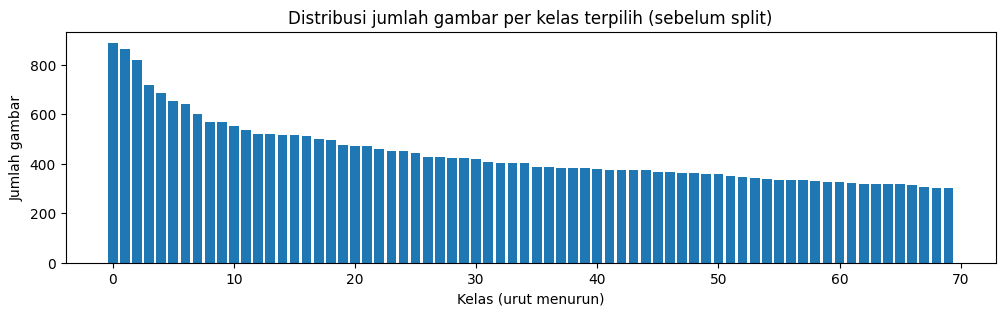

In [20]:
cfg = CONFIG["data"]

eligible = {c: f for c, f in class_files.items() if len(f) >= cfg["MIN_SAMPLES_PER_CLASS"]}
print(f"Kelas memenuhi minimum {cfg['MIN_SAMPLES_PER_CLASS']} gambar: {len(eligible)}")

if cfg["SELECTION_MODE"] == "top":
    ordered = sorted(eligible, key=lambda c: len(eligible[c]), reverse=True)
elif cfg["SELECTION_MODE"] == "first":
    ordered = sorted(eligible, key=int)
else:
    ordered = list(eligible); random.shuffle(ordered)

selected = ordered if cfg["NUM_CLASSES"] is None else ordered[:cfg["NUM_CLASSES"]]
selected_files = {c: eligible[c] for c in sorted(selected)}

sel_counts = [len(v) for v in selected_files.values()]
print(f"Kelas dipakai: {len(selected_files)} | total gambar: {sum(sel_counts)} "
      f"| min/maks per kelas: {min(sel_counts)}/{max(sel_counts)}")

plt.figure(figsize=(12, 3))
plt.bar(range(len(sel_counts)), sorted(sel_counts, reverse=True))
plt.title("Distribusi jumlah gambar per kelas terpilih (sebelum split)")
plt.xlabel("Kelas (urut menurun)"); plt.ylabel("Jumlah gambar")
plt.show()

## 7. Pembagian Data Train / Validation / Test
Data dibagi menjadi tiga subset karena masing-masing memiliki fungsi yang berbeda. **Train** digunakan untuk melatih bobot model, **validation** untuk memantau performa selama training dan mengatur callback, serta **test** untuk evaluasi akhir yang tidak dipakai selama training.

Pembagian dilakukan dengan rasio 70% / 15% / 15% dengan beberapa ketentuan:

- **Stratified**: karena jumlah gambar tiap kelas berbeda, pembagian dilakukan dengan `stratify` agar proporsi tiap kelas sama di ketiga subset.
- **Dua kali `train_test_split`**: fungsi ini hanya membagi data menjadi dua bagian. Data dibagi lebih dulu menjadi train (70%) dan sisanya (30%), kemudian sisanya dibagi sama besar menjadi validation dan test.
- **Pembagian pada daftar path file**, bukan menyalin file, sehingga lebih efisien dan memudahkan proses balancing.
- **`class_names` diurutkan dan ditetapkan di tahap ini** agar indeks kelas tidak berubah dan konsisten saat evaluasi dan inference.

Hasil pembagian: **21.533 gambar train, 4.614 gambar validation, dan 4.615 gambar test**.

In [21]:
from sklearn.model_selection import train_test_split

paths, labels = [], []
for c, fl in selected_files.items():
    paths += fl; labels += [c] * len(fl)

split_ratio = cfg["SPLIT"]
p_train, p_tmp, y_train, y_tmp = train_test_split(
    paths, labels, test_size=1 - split_ratio[0], stratify=labels, random_state=cfg["SEED"])
p_val, p_test, y_val, y_test = train_test_split(
    p_tmp, y_tmp, test_size=split_ratio[2] / (split_ratio[1] + split_ratio[2]),
    stratify=y_tmp, random_state=cfg["SEED"])

print(f"Train: {len(p_train)} | Val: {len(p_val)} | Test: {len(p_test)}")

# Urutan indeks kelas TETAP (tidak berubah oleh balancing di bawah) -> konsisten utk inference
class_names = sorted(selected_files.keys())
cls_to_idx = {c: i for i, c in enumerate(class_names)}

Train: 21533 | Val: 4614 | Test: 4615


## 8. Penyeimbangan (Balancing) Data Train
Jumlah gambar per kelas yang tidak merata membuat model cenderung lebih sering memprediksi kelas yang datanya banyak. Karena itu, data train diseimbangkan ke `TARGET_PER_CLASS` sebesar 150 gambar per kelas.

Balancing dilakukan **setelah pembagian data dan hanya pada data train**. Oversampling menduplikasi gambar, sehingga apabila dilakukan sebelum pembagian, salinan gambar yang sama dapat masuk ke train dan test sekaligus (*data leakage*) dan membuat hasil evaluasi terlihat lebih baik dari kenyataan. Data validation dan test dibiarkan pada distribusi aslinya agar evaluasi tetap objektif.

Metode yang digunakan adalah `both`, yaitu gabungan dua teknik:

- **Undersampling**: kelas dengan gambar lebih dari target diambil sampel acaknya tanpa pengembalian.
- **Oversampling**: kelas dengan gambar kurang dari target ditambah dengan pengambilan acak dengan pengembalian. Duplikat ini tidak identik saat training karena augmentasi acak pada tahap 11 mengubah tampilan tiap gambar.

Gabungan keduanya dipilih agar tidak terlalu banyak data yang dibuang (jika hanya undersampling) dan tidak terlalu banyak data yang diduplikasi (jika hanya oversampling). Generator acak diberi seed agar hasilnya konsisten. Setelah balancing, jumlah gambar train berubah dari 21.533 menjadi **10.500** (70 kelas × 150 gambar).

Balancing: aktif (both) | target/kelas: 150
Train sebelum: 21533 gambar | sesudah: 10500 gambar


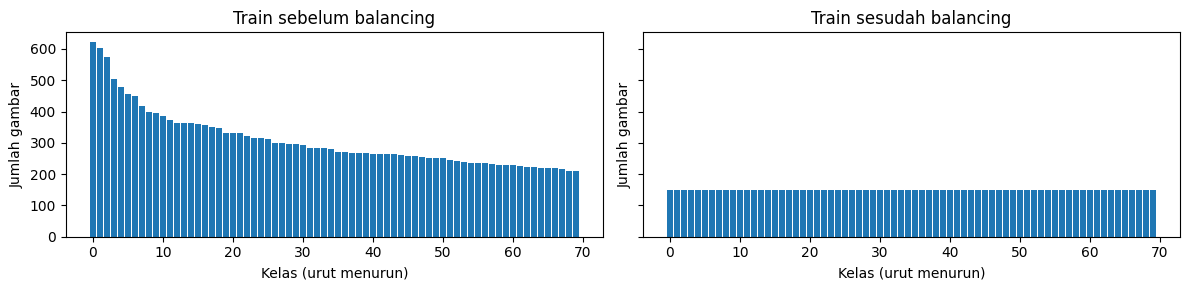

In [22]:
bal = CONFIG["balance"]
rng = random.Random(cfg["SEED"])

def balance_train(paths, labels, target, method):
    by_class = {}
    for p, y in zip(paths, labels):
        by_class.setdefault(y, []).append(p)
    before = {c: len(v) for c, v in by_class.items()}

    out_paths, out_labels = [], []
    for c, plist in by_class.items():
        n = len(plist)
        if n > target and method in ("undersample", "both"):
            plist = rng.sample(plist, target)
        elif n < target and method in ("oversample", "both"):
            plist = plist + rng.choices(plist, k=target - n)
        out_paths += plist
        out_labels += [c] * len(plist)
    after = dict(Counter(out_labels))
    return out_paths, out_labels, before, after

if bal["ENABLED"]:
    p_train_bal, y_train_bal, dist_before, dist_after = balance_train(
        p_train, y_train, bal["TARGET_PER_CLASS"], bal["METHOD"])
else:
    p_train_bal, y_train_bal = p_train, y_train
    dist_before = dist_after = dict(Counter(y_train))

print(f"Balancing: {'aktif (' + bal['METHOD'] + ')' if bal['ENABLED'] else 'tidak aktif'} "
      f"| target/kelas: {bal['TARGET_PER_CLASS']}")
print(f"Train sebelum: {len(p_train)} gambar | sesudah: {len(p_train_bal)} gambar")

fig, ax = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
ax[0].bar(range(len(dist_before)), sorted(dist_before.values(), reverse=True)); ax[0].set_title("Train sebelum balancing")
ax[1].bar(range(len(dist_after)), sorted(dist_after.values(), reverse=True)); ax[1].set_title("Train sesudah balancing")
for a in ax:
    a.set_xlabel("Kelas (urut menurun)"); a.set_ylabel("Jumlah gambar")
plt.tight_layout(); plt.show()

## 9. Pipeline `tf.data`
Pipeline `tf.data` digunakan agar proses pembacaan gambar berjalan paralel dengan proses training, sehingga GPU tidak menunggu data. Pipeline dibangun dari daftar path, bukan dari folder, sehingga hasil oversampling cukup berupa path yang berulang tanpa menduplikasi file.

**Langkah pemrosesan gambar (`_load_image`)**

- `decode_image(channels=3)` mengubah semua gambar menjadi RGB, karena terdapat gambar grayscale atau RGBA sedangkan model menerima 3 channel.
- `resize` menyeragamkan ukuran gambar sesuai `IMG_SIZE`.
- `set_shape` menyatakan ukuran tensor, karena `decode_image` tidak memberitahukan ukuran gambar kepada TensorFlow.
- `preprocess_input` menyesuaikan skala piksel dengan yang diharapkan EfficientNetB0. Model ini menerima piksel mentah 0–255 dan sudah memiliki layer normalisasi bawaan, sehingga **`Rescaling(1/255)` tidak digunakan** agar skala tidak berubah dua kali. Fungsi yang sama dipakai pada saat inference (tahap 18).

**Pengaturan dataset (`make_dataset`)**

- Label diubah menjadi indeks integer sesuai dengan loss `sparse_categorical_crossentropy` yang digunakan pada tahap 12.
- Pengacakan (`shuffle`) hanya dilakukan pada data train agar urutan data berbeda tiap epoch. Data validation dan test tidak diacak agar urutan prediksi sama dengan urutan label saat evaluasi (tahap 14).
- `batch` mengelompokkan data per `BATCH_SIZE`, dan `prefetch` menyiapkan batch berikutnya selagi batch saat ini diproses.
- `.cache()` hanya diterapkan pada validation dan test karena ukurannya kecil dan dipakai berulang. Data train tidak di-cache karena ukurannya besar dan berisi data duplikat, sehingga akan memboroskan memori.

In [23]:
IMG_SIZE = cfg["IMG_SIZE"]
BATCH_SIZE = cfg["BATCH_SIZE"]
AUTOTUNE = tf.data.AUTOTUNE

effnet_preprocess = tf.keras.applications.efficientnet.preprocess_input

def _load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img.set_shape((IMG_SIZE, IMG_SIZE, 3))
    img = effnet_preprocess(img)   # skala piksel konsisten utk EfficientNetB0
    return img, label

def make_dataset(paths, str_labels, training):
    idx_labels = [cls_to_idx[c] for c in str_labels]
    ds = tf.data.Dataset.from_tensor_slices((paths, idx_labels))
    if training:
        ds = ds.shuffle(buffer_size=len(paths), seed=cfg["SEED"], reshuffle_each_iteration=True)
    ds = ds.map(_load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(p_train_bal, y_train_bal, training=True)
val_ds = make_dataset(p_val, y_val, training=False).cache()
test_ds = make_dataset(p_test, y_test, training=False).cache()

print("Jumlah kelas:", len(class_names), "| contoh kode GBIF:", class_names[:5])

Jumlah kelas: 70 | contoh kode GBIF: ['1035185', '1035195', '1035290', '1035434', '1035551']


## 10. Class Weight
*Class weight* adalah cara lain untuk menangani ketidakseimbangan kelas, yaitu dengan memberi bobot loss yang lebih besar pada kelas yang datanya sedikit. Bobot dihitung dengan mode `"balanced"`, yaitu berbanding terbalik dengan jumlah data tiap kelas.

Pada penelitian ini fitur tersebut **tidak digunakan** (`USE_CLASS_WEIGHT = False`) karena data train sudah diseimbangkan pada tahap 8. Penggunaan keduanya sekaligus berisiko mengoreksi ketidakseimbangan dua kali. Opsi ini tetap disediakan apabila balancing dinonaktifkan.

In [24]:
from sklearn.utils.class_weight import compute_class_weight

if CONFIG["train"]["USE_CLASS_WEIGHT"]:
    y_train_idx = np.array([cls_to_idx[c] for c in y_train_bal])
    cw = compute_class_weight("balanced", classes=np.arange(len(class_names)), y=y_train_idx)
    class_weight = {i: float(w) for i, w in enumerate(cw)}
    print("Rentang class weight:", round(min(cw), 2), "-", round(max(cw), 2))
else:
    class_weight = None
    print("Class weight dinonaktifkan (CONFIG['train']['USE_CLASS_WEIGHT'] = False).")

Class weight dinonaktifkan (CONFIG['train']['USE_CLASS_WEIGHT'] = False).


## 11. Arsitektur Transfer Learning (EfficientNetB0)
Model dibangun dengan pendekatan *transfer learning*. Melatih CNN dari awal membutuhkan data yang banyak dan mudah mengalami overfitting. EfficientNetB0 sudah dilatih pada dataset ImageNet, sehingga fitur dasar seperti tepi, tekstur, dan bentuk sudah dikenali dan hanya perlu disesuaikan dengan kelas serangga. EfficientNetB0 dipilih karena akurasinya baik dengan jumlah parameter yang relatif kecil, sehingga sesuai untuk GPU Colab.

**Komponen model dan alasan penggunaannya**

- **Augmentasi di dalam model** (`RandomFlip`, `RandomRotation`, `RandomZoom`, `RandomTranslation`, `RandomContrast`) menambah variasi gambar saat training agar model tidak menghafal data. Karena berupa layer Keras, augmentasi aktif saat training dan nonaktif saat evaluasi dan prediksi.
- **`include_top=False`** membuang layer klasifikasi asli ImageNet (1000 kelas) karena penelitian ini memiliki kelas sendiri.
- **`training=False` pada backbone** menjaga layer `BatchNormalization` tetap memakai statistik hasil pretraining. Apabila tidak, statistik tersebut dapat berubah akibat data yang relatif kecil dan merusak fitur pretrained, termasuk saat fine-tuning.
- **`GlobalAveragePooling2D`** meringkas setiap feature map menjadi satu nilai. Parameternya jauh lebih sedikit dibandingkan `Flatten`, sehingga risiko overfitting lebih kecil.
- **`Dropout`** menonaktifkan sebagian neuron secara acak saat training agar model tidak bergantung pada neuron tertentu.
- **`Dense(256, activation="relu")`** mempelajari kombinasi fitur untuk kelas serangga. ReLU dipilih karena menambahkan non-linearitas (tanpa itu, layer yang ditumpuk hanya setara dengan satu transformasi linear), komputasinya ringan, dan lebih jarang mengalami masalah *vanishing gradient* dibandingkan sigmoid atau tanh.
- **`Dense(num_classes, activation="softmax")`** digunakan karena tugasnya adalah klasifikasi multi-kelas dengan satu label benar untuk setiap gambar. Softmax mengubah keluaran menjadi probabilitas yang berjumlah 1, sehingga dapat dibaca sebagai tingkat keyakinan per kelas dan sesuai dipasangkan dengan loss crossentropy.

**Fungsi `set_fine_tune_mode()`** mengatur layer backbone yang dilatih. Pada fine-tuning hanya sejumlah `FINE_TUNE_AT` layer terakhir yang dibuka, karena layer awal berisi fitur umum yang sudah baik sedangkan layer akhir berisi fitur yang lebih spesifik dan lebih perlu disesuaikan. Layer `BatchNormalization` tetap dibekukan dengan alasan yang sama seperti di atas.

Ringkasan model pada keluaran di bawah (dengan backbone dibekukan) menunjukkan total **4.395.497 parameter**, terdiri dari 345.926 parameter yang dilatih (head klasifikasi) dan 4.049.571 parameter yang dibekukan (backbone).

In [25]:
def build_model(num_classes, img_size, freeze_backbone=True):
    tl = CONFIG["transfer_learning"]; aug = CONFIG["augment"]; head = CONFIG["model"]

    inputs = layers.Input(shape=(img_size, img_size, 3), name="input_image")
    x = layers.RandomFlip(aug["FLIP"])(inputs)
    x = layers.RandomRotation(aug["ROTATION"])(x)
    x = layers.RandomZoom(aug["ZOOM"])(x)
    x = layers.RandomTranslation(aug["TRANSLATION"], aug["TRANSLATION"])(x)
    x = layers.RandomContrast(aug["CONTRAST"])(x)

    backbone = tf.keras.applications.EfficientNetB0(
        include_top=False, weights=tl["WEIGHTS"], input_shape=(img_size, img_size, 3),
    )
    backbone._name = "efficientnet_backbone"   # nama tetap -> mudah dicari lagi setelah load_model
    backbone.trainable = not freeze_backbone

    x = backbone(x, training=False)            # selalu False, lihat catatan di atas
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(head["HEAD_DROPOUT"])(x)
    x = layers.Dense(head["HEAD_UNITS"], activation="relu")(x)
    x = layers.Dropout(head["HEAD_DROPOUT"])(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="cnn_serangga_effnet")
    return model, backbone


def set_fine_tune_mode(backbone, fine_tune_enabled, fine_tune_at):
    # Terapkan status freeze/fine-tune ke backbone sesuai CONFIG saat ini.
    # BatchNormalization selalu dibekukan (trainable=False) walau fine-tuning aktif,
    # agar statistik BN hasil pretraining ImageNet tidak rusak.
    if not fine_tune_enabled:
        backbone.trainable = False
        return
    backbone.trainable = True
    cutoff = max(len(backbone.layers) - fine_tune_at, 0)
    for i, layer in enumerate(backbone.layers):
        if i < cutoff or isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
        else:
            layer.trainable = True


# Pratinjau arsitektur (model latihan sesungguhnya dibangun/di-resume di sel training bagian 12)
_preview_model, _preview_backbone = build_model(len(class_names), IMG_SIZE,
                                                 freeze_backbone=CONFIG["transfer_learning"]["FREEZE_BACKBONE"])
_preview_model.summary()
del _preview_model, _preview_backbone

Model: "cnn_serangga_effnet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_2 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_2               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_2 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_2            │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_2               │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 70)             │        17,990 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,395,497 (16.77 MB)

 Trainable params: 345,926 (1.32 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 12. Training dan Resume
**Strategi dua fase.** Head klasifikasi yang baru berisi bobot acak, sedangkan backbone sudah terlatih. Apabila seluruh bagian dilatih sejak awal, gradien yang besar dari head yang masih acak dapat merusak bobot pretrained. Oleh karena itu, training dilakukan dalam dua fase: (1) *feature extraction*, yaitu hanya head yang dilatih dengan backbone dibekukan, dan (2) *fine-tuning*, yaitu sebagian layer akhir backbone dibuka dengan learning rate yang lebih kecil.

**Konfigurasi kompilasi dan callback**

- **Adam** digunakan sebagai optimizer karena umum dipakai dan relatif tidak sensitif terhadap nilai learning rate awal.
- **`sparse_categorical_crossentropy`** adalah loss standar untuk klasifikasi multi-kelas dengan keluaran softmax. Varian *sparse* dipakai karena label berupa indeks integer, bukan one-hot.
- **Metrik `accuracy` dan `top5_acc`**. Top-5 accuracy berguna karena jumlah kelas cukup banyak dan beberapa spesies mirip, sehingga prediksi yang benar di lima teratas tetap menunjukkan kualitas model.
- **`ModelCheckpoint`** dua kali: `last_checkpoint` disimpan tiap epoch untuk melanjutkan training, sedangkan `best_checkpoint` hanya menyimpan bobot dengan `val_accuracy` tertinggi untuk evaluasi.
- **`EarlyStopping`** (memantau `val_loss`, dengan `restore_best_weights=True`) menghentikan training ketika model mulai overfitting.
- **`ReduceLROnPlateau`** menurunkan learning rate ketika `val_loss` tidak membaik, sehingga model dapat menyesuaikan bobot dengan lebih halus.
- **`HistoryLogger`** menyimpan riwayat training ke `history_log.json` agar kurva tetap utuh walaupun sesi terputus.

**Mekanisme resume.** Nilai `initial_epoch` dihitung otomatis dari riwayat training, sehingga sel ini dapat dijalankan ulang untuk melanjutkan training. `EPOCHS` adalah epoch **target**, bukan jumlah epoch tambahan.

**Pelaksanaan.** Fase feature extraction dijalankan hingga epoch ke-60. Selanjutnya `FINE_TUNE_ENABLED` diubah menjadi `True` dan `EPOCHS` dinaikkan menjadi 90 untuk fase fine-tuning. Keluaran di bawah merupakan sesi fine-tuning: training dilanjutkan dari epoch 61 dengan learning rate 1e-4 dan **15 dari 238 layer backbone dibuka** (dari 20 layer terakhir, layer `BatchNormalization` tetap dibekukan). `ReduceLROnPlateau` menurunkan learning rate secara bertahap hingga 2,5e-5. Pada fase ini `val_accuracy` naik dari 0,7503 (epoch 61) menjadi 0,8572 (epoch 88), yang merupakan nilai tertinggi dan disimpan sebagai `best_checkpoint`.

In [36]:
class HistoryLogger(keras.callbacks.Callback):
    # Akumulasi history training ke file JSON lintas sesi (untuk resume & plotting).
    def __init__(self, path):
        super().__init__()
        self.path = path
        self.log = json.load(open(path)) if os.path.exists(path) else {}

    def on_epoch_end(self, epoch, logs=None):
        for k, v in (logs or {}).items():
            self.log.setdefault(k, []).append(float(v))
        with open(self.path, "w") as f:
            json.dump(self.log, f, indent=2)

tl = CONFIG["transfer_learning"]
tr = CONFIG["train"]

history_logger = HistoryLogger(HISTORY_PATH)
initial_epoch = len(history_logger.log.get("loss", []))   # otomatis dari riwayat, bukan hardcode

if os.path.exists(LAST_CKPT):
    print(f"Melanjutkan training dari epoch {initial_epoch} (memuat {LAST_CKPT})")
    model = keras.models.load_model(LAST_CKPT)


    # Cari backbone dengan nama fleksibel
    backbone = None
    for layer in model.layers:
        if "efficientnet" in layer.name.lower():
            backbone = layer
            break

    if backbone is None:
        raise ValueError("Backbone EfficientNet tidak ditemukan di model yang di-load!")

    # Rename kembali ke nama yang konsisten
    backbone._name = "efficientnet_backbone"


else:
    print("Memulai training dari awal (checkpoint sebelumnya tidak ditemukan)")
    model, backbone = build_model(len(class_names), IMG_SIZE, freeze_backbone=tl["FREEZE_BACKBONE"])

# Terapkan mode freeze/fine-tune sesuai CONFIG saat sel ini dijalankan.
set_fine_tune_mode(backbone, tl["FINE_TUNE_ENABLED"], tl["FINE_TUNE_AT"])
current_lr = tl["FINE_TUNE_LR"] if tl["FINE_TUNE_ENABLED"] else tr["LEARNING_RATE"]
n_trainable = sum(1 for l in backbone.layers if l.trainable)
mode_desc = (f"FINE-TUNING ({n_trainable}/{len(backbone.layers)} layer backbone terbuka)"
             if tl["FINE_TUNE_ENABLED"] else "FEATURE EXTRACTION (backbone dibekukan penuh)")
print(f"Mode: {mode_desc} | learning rate: {current_lr} | target epoch: {tr['EPOCHS']}")

model.compile(
    optimizer=keras.optimizers.Adam(current_lr),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5_acc")],
)

callbacks = [
    keras.callbacks.ModelCheckpoint(LAST_CKPT, save_best_only=False, verbose=0),
    keras.callbacks.ModelCheckpoint(BEST_CKPT, monitor="val_accuracy", save_best_only=True, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=tr["EARLY_STOPPING_PATIENCE"],
                                   restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=tr["REDUCE_LR_FACTOR"],
                                       patience=tr["REDUCE_LR_PATIENCE"], min_lr=tr["REDUCE_LR_MIN_LR"], verbose=1),
    history_logger,
]

model.fit(
    train_ds, validation_data=val_ds,
    initial_epoch=initial_epoch, epochs=tr["EPOCHS"],
    callbacks=callbacks, class_weight=class_weight,
)

Melanjutkan training dari epoch 60 (memuat /content/drive/MyDrive/insect_cnn_effnet_output/last_checkpoint.keras)
Mode: FINE-TUNING (15/238 layer backbone terbuka) | learning rate: 0.0001 | target epoch: 90
Epoch 61/90
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.7541 - loss: 0.7674 - top5_acc: 0.9631
Epoch 61: val_accuracy improved from None to 0.75033, saving model to /content/drive/MyDrive/insect_cnn_effnet_output/best_checkpoint.keras

Epoch 61: finished saving model to /content/drive/MyDrive/insect_cnn_effnet_output/best_checkpoint.keras
329/329 ━━━━━━━━━━━━━━━━━━━━ 56s 133ms/step - accuracy: 0.7587 - loss: 0.7518 - top5_acc: 0.9673 - val_accuracy: 0.7503 - val_loss: 0.7643 - val_top5_acc: 0.9651 - learning_rate: 1.0000e-04
Epoch 62/90
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.7932 - loss: 0.6577 - top5_acc: 0.9738
Epoch 62: val_accuracy improved from 0.75033 to 0.78175, saving model to /content/drive/MyDrive/insect_cnn_effnet_output/best_checkpoint.keras


## 13. Kurva Training
Kurva akurasi dan loss untuk data train dan validation diplot berdampingan karena selisih keduanya menunjukkan kondisi model: apabila keduanya membaik, model belajar dengan baik; apabila train terus membaik sementara validation mendatar atau memburuk, terjadi overfitting; dan apabila keduanya rendah, model masih *underfitting*.

Data kurva dibaca dari `history_log.json`, bukan dari objek `history` hasil `fit()`, karena objek tersebut hanya mencakup sesi training terakhir. Dengan file log, riwayat dari fase feature extraction dan fine-tuning tampil dalam satu grafik.

**Analisis.** Pada fase feature extraction (epoch 1 sampai 60), akurasi validation naik cepat pada awal training kemudian melandai di sekitar 0,70–0,72. Setelah fine-tuning dimulai (epoch 61), akurasi train dan validation kembali naik dan loss turun. Pada epoch terakhir, akurasi train mencapai 0,9186 dan akurasi validation 0,8526, sedangkan loss train 0,2282 dan loss validation 0,4686. Selisih sekitar 7 poin akurasi antara train dan validation menunjukkan adanya overfitting ringan.

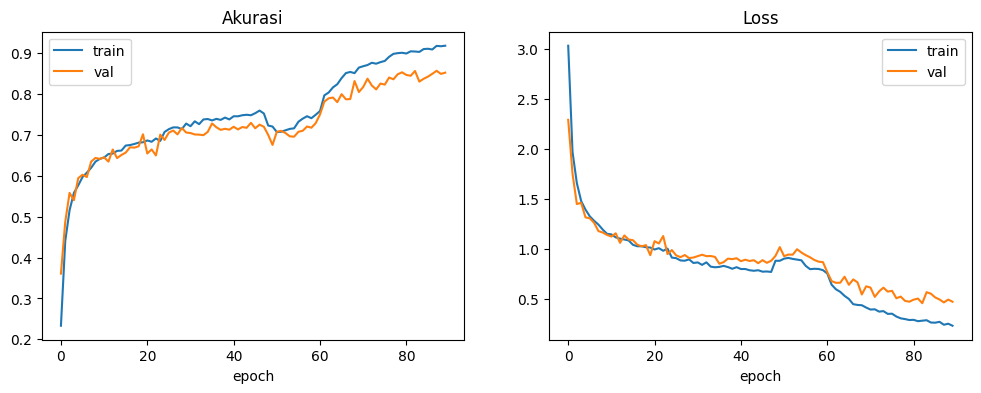

In [37]:
with open(HISTORY_PATH) as f:
    h = json.load(f)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["accuracy"], label="train"); ax[0].plot(h["val_accuracy"], label="val")
ax[0].set_title("Akurasi"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h["loss"], label="train"); ax[1].plot(h["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

## 14. Evaluasi pada Data Test
Evaluasi akhir dilakukan pada data test yang tidak pernah dipakai selama training maupun pemilihan model, sehingga hasilnya lebih mendekati performa model pada data baru. Model yang dievaluasi adalah `best_checkpoint.keras`, karena bobot pada epoch terakhir belum tentu merupakan bobot terbaik.

Beberapa metrik digunakan sekaligus:

- **Accuracy** memberikan gambaran umum ketepatan prediksi.
- **Top-5 accuracy** menilai apakah kelas yang benar berada di lima prediksi teratas.
- **Macro F1** merata-ratakan F1 tiap kelas dengan bobot sama, sehingga kelas dengan data sedikit tidak tertutup oleh kelas dengan data banyak.
- **`classification_report`** menampilkan precision, recall, dan F1 per kelas untuk mengetahui kelas yang performanya rendah.

Kelas prediksi diambil dengan `np.argmax` dari probabilitas softmax. Label asli (`y_true`) diambil dari `test_ds` yang sama, dan urutannya sesuai dengan prediksi karena `test_ds` tidak diacak. Parameter `zero_division=0` mencegah error apabila ada kelas yang tidak pernah diprediksi.

**Hasil.** Pada data test (4.615 gambar) diperoleh loss 0,4929, **accuracy 0,8468**, **top-5 accuracy 0,9881**, dan **macro F1 0,8410**. Beberapa kelas dikenali dengan sangat baik, misalnya kelas 4308815, 5753697, dan 5754974 dengan F1 sebesar 1,00. Kelas dengan F1 terendah adalah kelas 5872111 (0,48), diikuti beberapa kelas dengan F1 sekitar 0,61 sampai 0,66, seperti 6097882, 7873810, dan 1036154.

In [38]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score

eval_model = keras.models.load_model(BEST_CKPT)

test_loss, test_acc, test_top5 = eval_model.evaluate(test_ds, verbose=0)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f} | Top-5 accuracy: {test_top5:.4f}")

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(eval_model.predict(test_ds, verbose=0), axis=1)
print(f"Macro F1: {f1_score(y_true, y_pred, average='macro'):.4f}\n")
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

Test loss: 0.4929 | Test accuracy: 0.8468 | Top-5 accuracy: 0.9881
Macro F1: 0.8410

              precision    recall  f1-score   support

     1035185       0.91      0.88      0.89        90
     1035195       0.95      0.81      0.88        86
     1035290       0.92      0.94      0.93        71
     1035434       0.75      0.69      0.72        58
     1035551       0.99      1.00      0.99        78
     1035578       0.88      0.97      0.92        72
     1035864       0.87      0.96      0.92        85
     1035931       0.91      0.81      0.86       129
     1036154       0.77      0.53      0.63        81
     1036192       0.77      0.69      0.73        68
     1036216       0.91      0.84      0.87       103
     1036255       0.76      0.83      0.80        47
     1036893       0.97      0.96      0.96        71
     1037319       0.70      0.62      0.65        52
     4308789       0.65      0.96      0.78        54
     4308806       0.89      0.62      0.73       

## 15. Confusion Matrix
Metrik tunggal seperti accuracy tidak menunjukkan kelas mana yang sering tertukar dengan kelas lain. Confusion matrix digunakan untuk melihat hal tersebut, dengan baris sebagai kelas aktual dan kolom sebagai kelas prediksi.

- Nilai **dinormalisasi per baris** karena jumlah gambar test setiap kelas berbeda. Dengan proporsi, warna antar kelas dapat dibandingkan secara adil, dan diagonal yang terang menunjukkan kelas yang dikenali dengan baik.
- Pembagi diberi nilai minimal 1 (`np.maximum(..., 1)`) untuk mencegah pembagian dengan nol pada kelas tanpa sampel.
- Diagonal pada salinan matriks diisi nol sehingga yang tersisa hanya kesalahan prediksi, kemudian 10 pasangan kelas dengan kesalahan terbanyak ditampilkan.

**Hasil.** Diagonal yang dominan pada heatmap menunjukkan sebagian besar gambar diprediksi dengan benar. Kesalahan terbanyak terjadi pada gambar kelas 6097882 yang diprediksi sebagai kelas 5872127 (23 gambar), diikuti kelas 7873810 yang diprediksi sebagai 7975487 (20 gambar), serta kelas 7508714 menjadi 7975487 dan kelas 4475140 menjadi 4475213 (masing-masing 19 gambar). Pasangan-pasangan ini dapat menjadi bahan analisis lanjutan untuk melihat spesies yang secara visual sulit dibedakan.

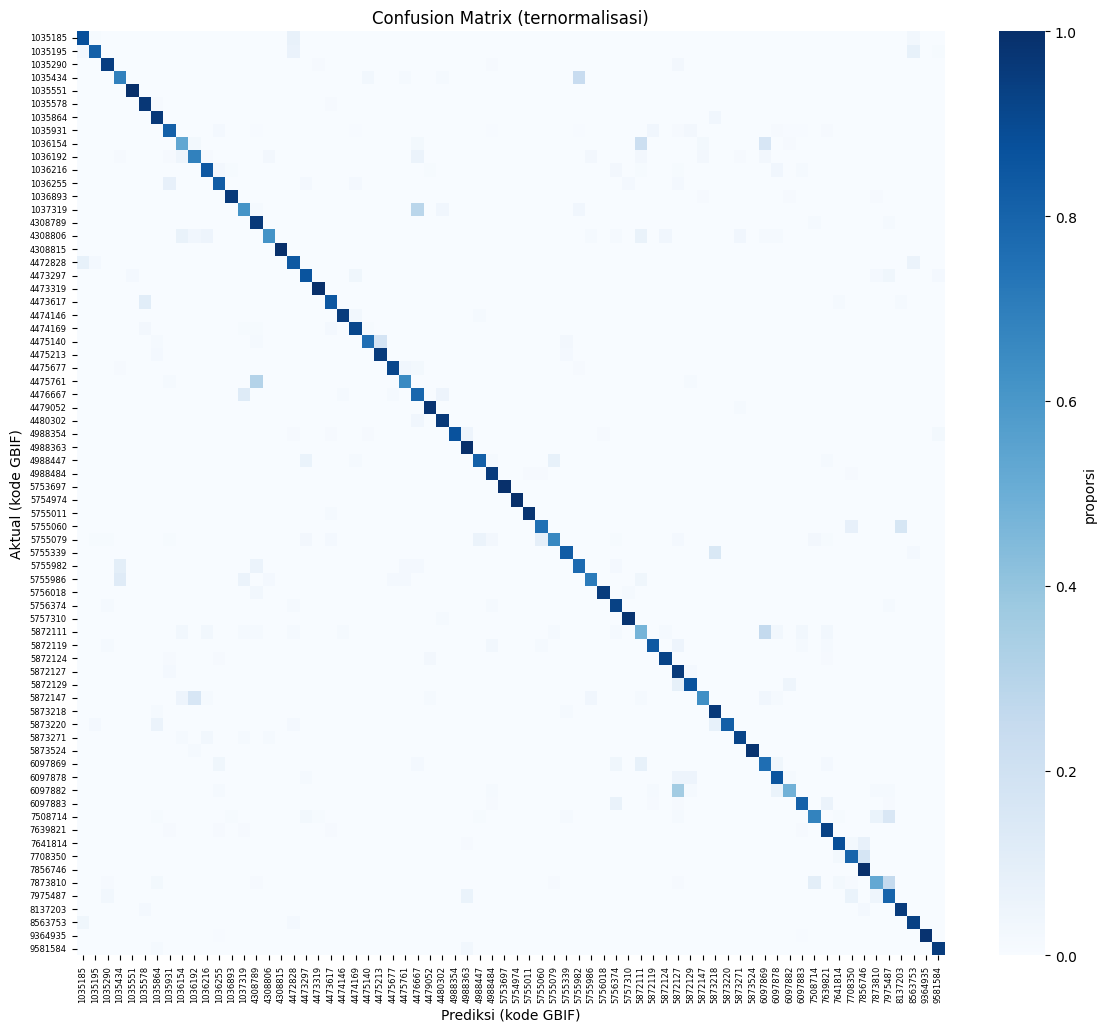

10 kesalahan paling sering (jumlah, aktual -> prediksi):
   23x  6097882 -> 5872127
   20x  7873810 -> 7975487
   19x  7508714 -> 7975487
   19x  4475140 -> 4475213
   18x  1036154 -> 5872111
   16x  5872111 -> 6097869
   16x  4475761 -> 4308789
   15x  1037319 -> 4476667
   14x  1035434 -> 5755982
   13x  7708350 -> 7856746


In [39]:
import seaborn as sns

cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

plt.figure(figsize=(14, 12))
sns.heatmap(cm_norm, cmap="Blues", xticklabels=class_names, yticklabels=class_names,
            cbar_kws={"label": "proporsi"})
plt.xticks(fontsize=6, rotation=90); plt.yticks(fontsize=6)
plt.xlabel("Prediksi (kode GBIF)"); plt.ylabel("Aktual (kode GBIF)"); plt.title("Confusion Matrix (ternormalisasi)")
plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted(((off[i, j], class_names[i], class_names[j])
                for i in range(len(off)) for j in range(len(off)) if off[i, j] > 0), reverse=True)[:10]
print("10 kesalahan paling sering (jumlah, aktual -> prediksi):")
for n, a, b in pairs:
    print(f"  {n:>3}x  {a} -> {b}")

## 16. Penyimpanan Model Final & Metadata
Dua jenis keluaran disimpan ke Google Drive:

- **`model_cnn_serangga_final.keras`**: salinan bobot terbaik dengan nama yang lebih jelas, agar mudah digunakan di luar notebook.
- **`class_names.json`**: berisi daftar kelas, pemetaan indeks ke kode GBIF, ukuran gambar, salinan `CONFIG`, dan metrik test. Model hanya menghasilkan indeks (0, 1, 2, dst.), sehingga pemetaan kelas perlu disimpan bersama model. Ukuran gambar dan konfigurasi disimpan agar preprocessing saat inference sama dengan saat training.

Metadata disimpan dalam format JSON karena sederhana, mudah dibaca, dan dapat dibuka dari program lain. Berdasarkan keluaran, folder output berisi lima file: `best_checkpoint.keras`, `class_names.json`, `history_log.json`, `last_checkpoint.keras`, dan `model_cnn_serangga_final.keras`.

In [30]:
FINAL_MODEL_PATH = os.path.join(OUTPUT_DIR, "model_cnn_serangga_final.keras")
shutil.copy2(BEST_CKPT, FINAL_MODEL_PATH)

metadata = {
    "img_size": IMG_SIZE,
    "class_names": class_names,
    "index_to_gbif": {str(i): c for i, c in enumerate(class_names)},
    "gbif_to_name": {},
    "config": CONFIG,
    "test_metrics": {"loss": float(test_loss), "accuracy": float(test_acc), "top5_accuracy": float(test_top5)},
}
with open(CLASS_NAMES_PATH, "w") as f:
    json.dump(metadata, f, indent=2)

print("Tersimpan di:", OUTPUT_DIR)
print(sorted(os.listdir(OUTPUT_DIR)))

Tersimpan di: /content/drive/MyDrive/insect_cnn_effnet_output
['best_checkpoint.keras', 'class_names.json', 'history_log.json', 'last_checkpoint.keras', 'model_cnn_serangga_final.keras']


## 17. Pengambilan Nama Spesies dari GBIF API
Label yang digunakan model berupa kode GBIF sehingga hasil prediksi kurang mudah dipahami. Tahap ini mengambil nama spesies dari GBIF API dan menyimpannya pada `gbif_to_name` di metadata.

- Tahap ini bersifat opsional (`FETCH_NAMES`) karena membutuhkan koneksi internet dan tidak memengaruhi training maupun evaluasi model.
- Blok `try/except` dan `timeout=10` digunakan agar kegagalan pada satu kode (misalnya jaringan lambat atau kode tidak ditemukan) tidak menghentikan seluruh proses. Kode yang gagal diisi `"unknown"`.
- Nama `canonicalName` digunakan terlebih dahulu karena lebih ringkas, dan `scientificName` menjadi cadangan.

Sebagai contoh, kode 1035185 sampai 1035551 berturut-turut dipetakan ke *Amara aenea*, *Amara familiaris*, *Loricera pilicornis*, *Bradycellus harpalinus*, dan *Elaphrus riparius*.

In [40]:
FETCH_NAMES = True

if FETCH_NAMES:
    import requests
    for c in class_names:
        try:
            r = requests.get(f"https://api.gbif.org/v1/species/{c}", timeout=10)
            d = r.json()
            metadata["gbif_to_name"][c] = d.get("canonicalName") or d.get("scientificName") or "unknown"
        except Exception:
            metadata["gbif_to_name"][c] = "unknown"
    with open(CLASS_NAMES_PATH, "w") as f:
        json.dump(metadata, f, indent=2)
    print({k: metadata["gbif_to_name"][k] for k in class_names[:5]})

{'1035185': 'Amara aenea', '1035195': 'Amara familiaris', '1035290': 'Loricera pilicornis', '1035434': 'Bradycellus harpalinus', '1035551': 'Elaphrus riparius'}


## 18. Contoh Inference pada Satu Gambar
Tahap ini menunjukkan penggunaan model final untuk memprediksi satu gambar, sebagaimana penggunaan model pada kondisi nyata.

- **Preprocessing disamakan dengan training**: gambar di-resize ke `img_size` dari metadata dan diproses dengan `preprocess_input` yang sama seperti pada tahap 9. Apabila berbeda, skala piksel tidak sesuai dan akurasi prediksi menurun.
- **`[None, ...]`** menambahkan dimensi batch karena model menerima input berbentuk (batch, tinggi, lebar, channel), sedangkan yang diprediksi hanya satu gambar.
- **Top-k prediksi** ditampilkan, bukan hanya satu, agar terlihat alternatif prediksi beserta tingkat keyakinannya. Kunci `index_to_gbif` berupa string (`str(i)`) karena JSON hanya mendukung kunci string.
- Gambar contoh dipilih secara acak dari data test, yaitu data yang tidak pernah dilihat model saat training.

**Hasil.** Pada contoh yang ditampilkan, label asli gambar adalah kode GBIF 8563753. Model memprediksi kelas yang sama (*Amara ovata*) dengan probabilitas 99,2%, sedangkan empat prediksi lainnya masing-masing memiliki probabilitas di bawah 1%. Contoh ini hanya memperlihatkan cara kerja inference pada satu gambar dan tidak mewakili performa keseluruhan model, yang ditunjukkan oleh hasil evaluasi pada tahap 14.

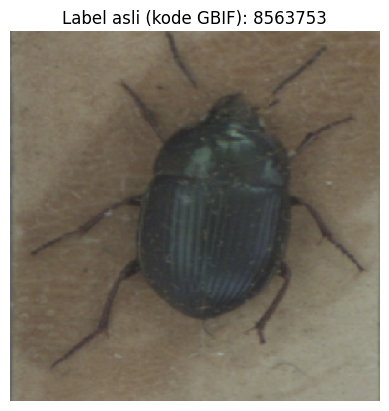

Kode GBIF    8563753 | Amara ovata                    |  99.2%
Kode GBIF    4988363 | Calathus fuscipes              |   0.5%
Kode GBIF    5753697 | Poecilus cupreus               |   0.2%
Kode GBIF    5873218 | Harpalus rubripes              |   0.1%
Kode GBIF    1035578 | Nebria brevicollis             |   0.0%


In [41]:
with open(CLASS_NAMES_PATH) as f:
    meta = json.load(f)
inference_model = keras.models.load_model(FINAL_MODEL_PATH)

def predict_image(path, model, meta, top_k=5):
    size = meta["img_size"]
    img = tf.keras.utils.load_img(path, target_size=(size, size))     # utk ditampilkan apa adanya
    arr = tf.keras.utils.img_to_array(img)
    arr = tf.keras.applications.efficientnet.preprocess_input(arr)[None, ...]  # utk input model
    probs = model.predict(arr, verbose=0)[0]
    results = []
    for i in np.argsort(probs)[::-1][:top_k]:
        gbif = meta["index_to_gbif"][str(i)]
        results.append((gbif, meta["gbif_to_name"].get(gbif, "-"), float(probs[i])))
    return img, results

# Contoh: ambil satu gambar acak dari daftar path test
example_idx = random.randrange(len(p_test))
example_path, example_label = p_test[example_idx], y_test[example_idx]

img, results = predict_image(example_path, inference_model, meta)
plt.imshow(img); plt.axis("off"); plt.title(f"Label asli (kode GBIF): {example_label}"); plt.show()
for gbif, name, p in results:
    print(f"Kode GBIF {gbif:>10} | {name:<30} | {p*100:5.1f}%")

## 19. Kesimpulan
Berdasarkan seluruh tahapan yang telah dilakukan, diperoleh kesimpulan sebagai berikut.

1. Model klasifikasi citra serangga berhasil dibangun menggunakan *transfer learning* EfficientNetB0 untuk **70 kelas** dengan total **30.762 gambar** dari dataset *Insect Identification from Habitus Images*.
2. Pada data test, model mencapai **accuracy 84,68%**, **top-5 accuracy 98,81%**, dan **macro F1 0,8410**. Nilai top-5 yang tinggi menunjukkan bahwa kelas yang benar hampir selalu berada di antara lima prediksi teratas.
3. Training dua fase memberikan peningkatan yang jelas. Pada fase *feature extraction*, akurasi validation melandai di sekitar 0,70–0,72, sedangkan setelah *fine-tuning* akurasi validation naik hingga sekitar 0,85.
4. Pembagian data secara *stratified*, penyeimbangan data hanya pada data train, serta augmentasi diterapkan untuk mengurangi pengaruh ketidakseimbangan jumlah gambar antar kelas dan risiko overfitting.

**Keterbatasan.** Terdapat selisih sekitar 7 poin akurasi antara data train (0,9186) dan validation (0,8526), yang menunjukkan overfitting ringan. Performa juga tidak merata antar kelas, misalnya kelas 5872111 hanya mencapai F1 0,48, dan kesalahan terbanyak terjadi antar kelas tertentu seperti 6097882 yang diprediksi sebagai 5872127. Selain itu, model hanya mencakup 70 dari 291 kelas yang tersedia pada dataset.

**Saran pengembangan.** Beberapa hal yang dapat dicoba pada penelitian selanjutnya adalah memperkuat augmentasi atau menambah data pada kelas yang performanya rendah, mencoba backbone yang lebih besar atau jumlah layer fine-tuning yang berbeda, serta menganalisis secara visual pasangan kelas yang sering tertukar.